In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Download the Kaggle Bank Marketing Dataset and use Pandas to load it into a DataFrame named bank_df, then display the first 10 rows and the DataFrame's info().

In [14]:
bank_df = pd.read_csv("C:/Users/Windows/OneDrive/Desktop/Pandas Dataset/banking.csv")

# Display the first 10 rows
print("First 10 Rows:")
print(bank_df.head(10))

First 10 Rows:
   age          job   marital          education  default housing loan  \
0   44  blue-collar   married           basic.4y  unknown     yes   no   
1   53   technician   married            unknown       no      no   no   
2   28   management    single  university.degree       no     yes   no   
3   39     services   married        high.school       no      no   no   
4   55      retired   married           basic.4y       no     yes   no   
5   30   management  divorced           basic.4y       no     yes   no   
6   37  blue-collar   married           basic.4y       no     yes   no   
7   39  blue-collar  divorced           basic.9y       no     yes   no   
8   36       admin.   married  university.degree       no      no   no   
9   27  blue-collar    single           basic.4y       no     yes   no   

    contact month day_of_week  ...  campaign  pdays  previous     poutcome  \
0  cellular   aug         thu  ...         1    999         0  nonexistent   
1  cellular   

In [15]:
# Display DataFrame information
print("\nDataFrame Information:")
print(bank_df.info())


DataFrame Information:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41

Use Seaborn's countplot to visualize how many customers in the dataset subscribed to a term deposit (column 'y'), and display the plot with appropriate axis labels.

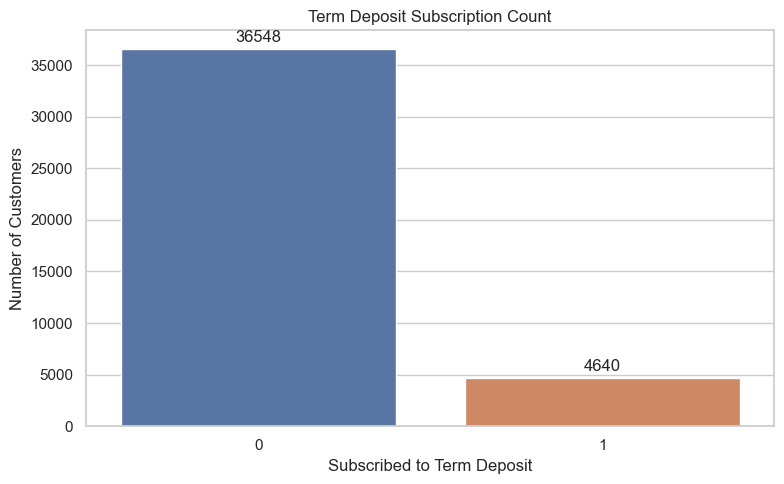

In [17]:
sns.set_theme(style='whitegrid')

# Create countplot
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=bank_df,
    x='y',
    hue='y',
    palette='deep',
    legend=False
)

# Add title and axis labels
plt.title('Term Deposit Subscription Count')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')

# Display count values above bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

# Display plot
plt.tight_layout()
plt.show()


Analyze the relationship between customer age and term deposit subscription by creating a Seaborn boxplot with 'y' on the x-axis and 'age' on the y-axis.<br><br><em><strong>Hint:</strong> This helps you see if certain age groups are more likely to subscribe.</em>

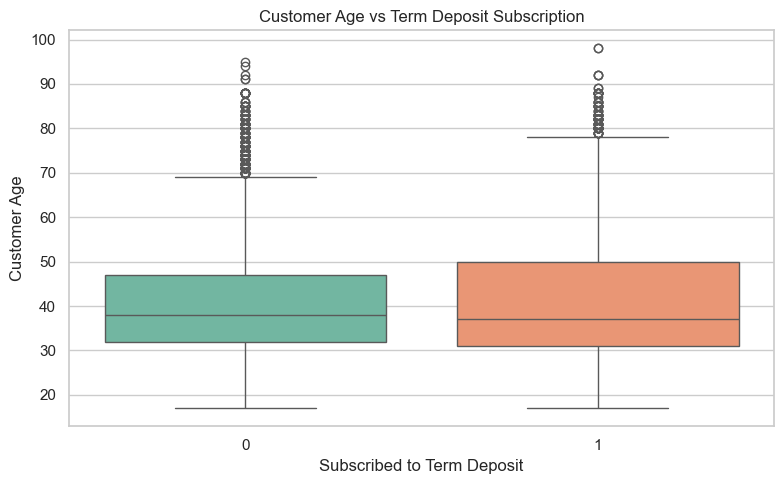

In [18]:
sns.set_theme(style='whitegrid')

# Create boxplot
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=bank_df,
    x='y',
    y='age',
    hue='y',
    palette='Set2',
    legend=False
)

# Add title and labels
plt.title('Customer Age vs Term Deposit Subscription')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Customer Age')

plt.tight_layout()
plt.show()

Create a bar plot using Seaborn to show the percentage of customers who subscribed to a term deposit for each education level (column 'education').<br><br><em><strong>Hint:</strong> Calculate the percentage for each group before plotting.</em>

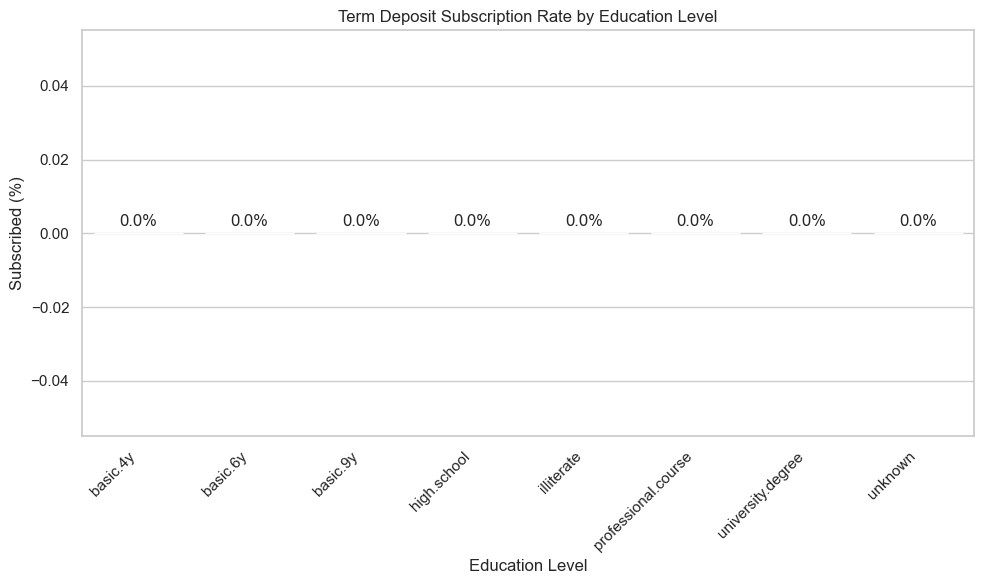

In [23]:
subscription_pct = (
    bank_df.groupby('education')['y']
      .apply(lambda s: (s == 'yes').mean() * 100)
      .reset_index(name='subscription_pct')
      .sort_values('subscription_pct', ascending=False)
)

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=subscription_pct, x='education', y='subscription_pct',
                 hue='education', palette='viridis', legend=False)

# Add percentage labels on top of the bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

ax.set_title('Term Deposit Subscription Rate by Education Level')
ax.set_xlabel('Education Level')
ax.set_ylabel('Subscribed (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Use ChatGPT or Copilot to suggest two additional visualizations that could help a fintech startup like Cred understand which users are most likely to buy a new savings product, then implement one of those visualizations using Seaborn.

  age_group  subscription_percentage
0     18-25                      0.0
1     26-35                      0.0
2     36-45                      0.0
3     46-55                      0.0
4       56+                      0.0


C:\Users\Windows\AppData\Local\Temp\ipykernel_14288\1969428541.py:32: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(0, age_percentage['subscription_percentage'].max() * 1.15)


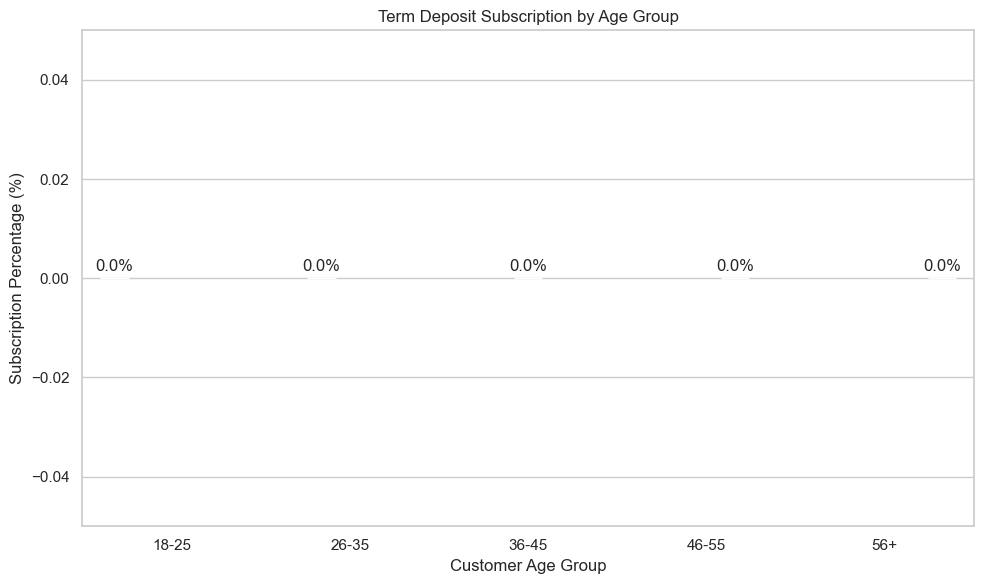

In [26]:
bank_df['age_group'] = pd.cut(
    bank_df['age'],
    bins=[17, 25, 35, 45, 55, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56+']
)

age_percentage = (
    bank_df.groupby('age_group', observed=True)['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .reset_index(name='subscription_percentage')
)
print(age_percentage)

sns.set_theme(style='whitegrid', palette='deep')

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=age_percentage,
    x='age_group',
    y='subscription_percentage',
    hue='age_group',
    palette='deep',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

ax.set_title('Term Deposit Subscription by Age Group')
ax.set_xlabel('Customer Age Group')
ax.set_ylabel('Subscription Percentage (%)')
ax.set_ylim(0, age_percentage['subscription_percentage'].max() * 1.15)

plt.tight_layout()
plt.show()